# 06 · Model development (PyTorch + Hugging Face)
* **Vision**: residual CNN (swap for a pretrained backbone on real data)
* **Text**: Hugging Face `BertModel` (2 layers, 96 hidden) with a WordPiece tokenizer trained by `tokenizers`; production would load `Bio_ClinicalBERT`
* **Numeric**: MLP with batch norm
* **Fusion**: per-patient gated attention over modality embeddings + modality dropout (robust to a missing modality)
* Class-weighted cross-entropy, label smoothing, AdamW + OneCycle, early stopping on validation macro-F1.
Unimodal baselines use the same code with a subset of modalities.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
FIG = ROOT / 'reports' / 'figures'
def show(name, width=900): display(Image(filename=str(FIG / f'{name}.png'), width=width))

In [2]:
import torch
from ad_mm.models.multimodal import MultimodalADNet
from ad_mm.config import CFG
m = MultimodalADNet(843, 22, 5, CFG['model'])
print(m.encoders['text'].bert.config)
print({k: sum(p.numel() for p in v.parameters()) for k, v in m.encoders.items()})

BertConfig {
  "add_cross_attention": false,
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "eos_token_id": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 96,
  "initializer_range": 0.02,
  "intermediate_size": 384,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 98,
  "model_type": "bert",
  "num_attention_heads": 4,
  "num_hidden_layers": 2,
  "pad_token_id": 0,
  "tie_word_embeddings": true,
  "transformers_version": "5.19.0",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 843
}

{'image': 320992, 'text': 326816, 'tabular': 26688}


{'tag': 'image', 'seed': 2026, 'modalities': ['image'], 'best_val_macro_f1': 0.5601533405526146, 'epochs_run': 48, 'train_seconds': 149.8, 'n_params': 346726}
{'tag': 'text', 'seed': 2026, 'modalities': ['text'], 'best_val_macro_f1': 0.7025703686994009, 'epochs_run': 38, 'train_seconds': 41.6, 'n_params': 352550}
{'tag': 'tabular', 'seed': 2026, 'modalities': ['tabular'], 'best_val_macro_f1': 0.8827768945416004, 'epochs_run': 21, 'train_seconds': 2.2, 'n_params': 52422}
{'tag': 'fusion', 'seed': 7, 'modalities': ['image', 'text', 'tabular'], 'best_val_macro_f1': 0.8952012432012433, 'epochs_run': 35, 'train_seconds': 151.8, 'n_params': 702165}


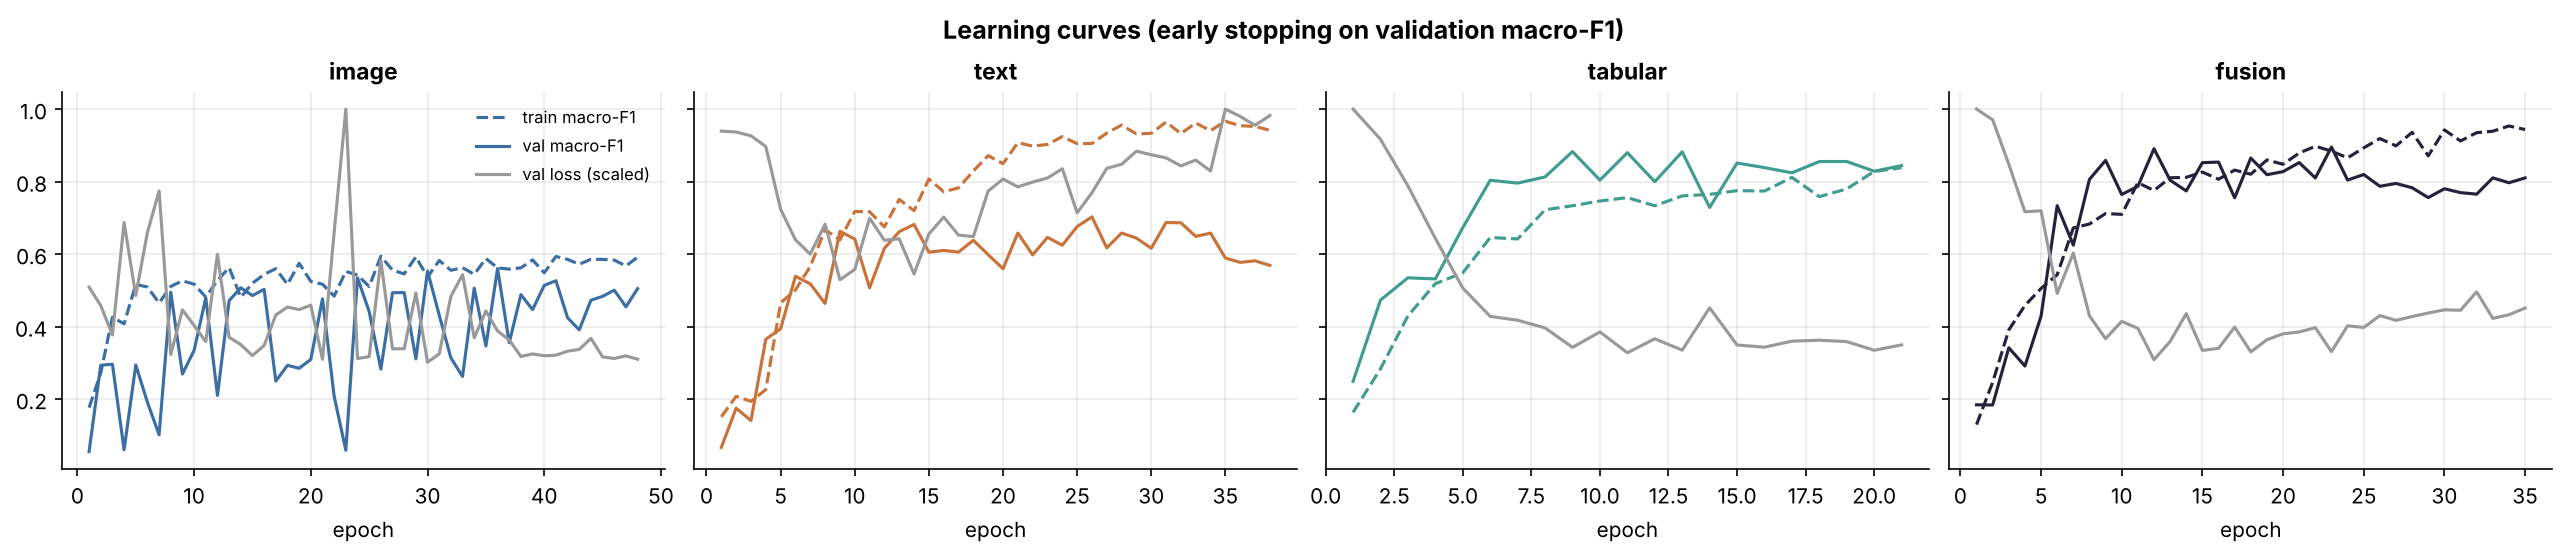

In [3]:
RETRAIN = False
if RETRAIN:
    from ad_mm.training.train import main; main()
for t in ['image', 'text', 'tabular', 'fusion']:
    print(json.load(open(ROOT / f'reports/metrics/history_{t}.json'))['meta'])
show('21_learning_curves', 1100)